In [1]:
!pip install ucimlrepo imbalanced-learn -q

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 4)

# fetch dataset (ID 891: CDC Diabetes Health Indicators)
cdc_diabetes_health_indicators = fetch_ucirepo(id=891)

# data (as pandas dataframes)
X = cdc_diabetes_health_indicators.data.features
y = cdc_diabetes_health_indicators.data.targets

# Join features and target into one table
df = pd.concat([X, y], axis=1)
target = "Diabetes_binary"
feature_cols = list(X.columns)
binary_features = [c for c in feature_cols if df[c].nunique() == 2]

print("Data loaded:", df.shape)

Data loaded: (253680, 22)


In [3]:
clean = df.drop_duplicates().copy()
clean["BMI"] = clean["BMI"].clip(upper=70)
print("Rows after cleaning:", len(clean))
print("Positive rate:", round(clean[target].mean() * 100, 1), "%")

Rows after cleaning: 229474
Positive rate: 15.3 %


Diabetes_binary
0    218334
1     35346
Name: count, dtype: int64
Diabetes_binary
0    86.1
1    13.9
Name: proportion, dtype: float64

Imbalance ratio: 6.2 : 1
Accuracy of always guessing 'no diabetes': 86.1 %


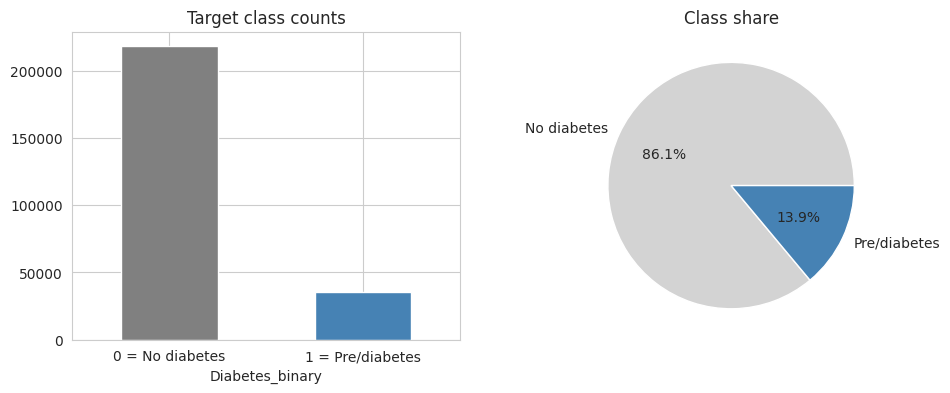

In [4]:
counts = df[target].value_counts()
print(counts)
print((df[target].value_counts(normalize=True) * 100).round(1))
print()
print("Imbalance ratio:", round(counts[0] / counts[1], 1), ": 1")
print("Accuracy of always guessing 'no diabetes':", round(counts[0] / len(df) * 100, 1), "%")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
counts.plot(kind="bar", ax=axes[0], color=["grey", "steelblue"])
axes[0].set_title("Target class counts")
axes[0].set_xticklabels(["0 = No diabetes", "1 = Pre/diabetes"], rotation=0)
axes[1].pie(counts, labels=["No diabetes", "Pre/diabetes"], autopct="%1.1f%%", colors=["lightgrey", "steelblue"])
axes[1].set_title("Class share")
plt.show()

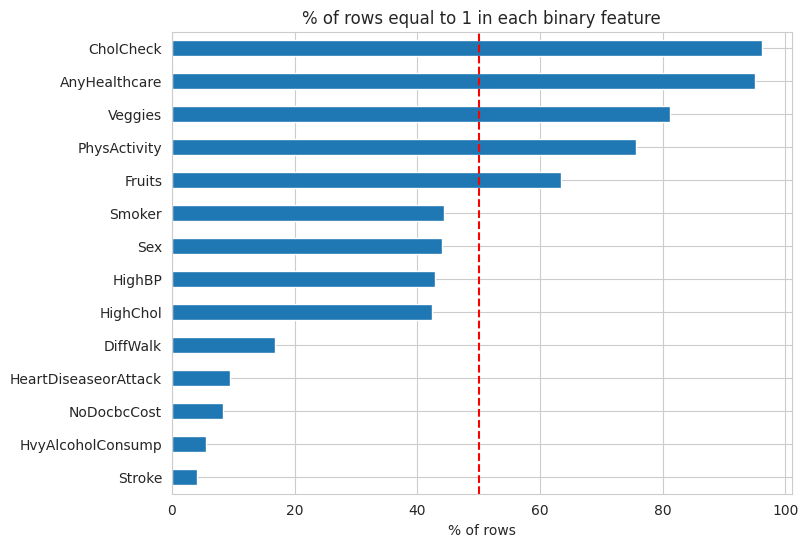

In [5]:
share_of_ones = (df[binary_features].mean() * 100).sort_values()
share_of_ones.plot(kind="barh", figsize=(8, 6))
plt.axvline(50, color="red", linestyle="--")
plt.title("% of rows equal to 1 in each binary feature")
plt.xlabel("% of rows")
plt.show()

Before SMOTE: {0: 155501, 1: 28078}
After SMOTE:  {0: 155501, 1: 155501}
Test set (untouched): {0: 38876, 1: 7019}


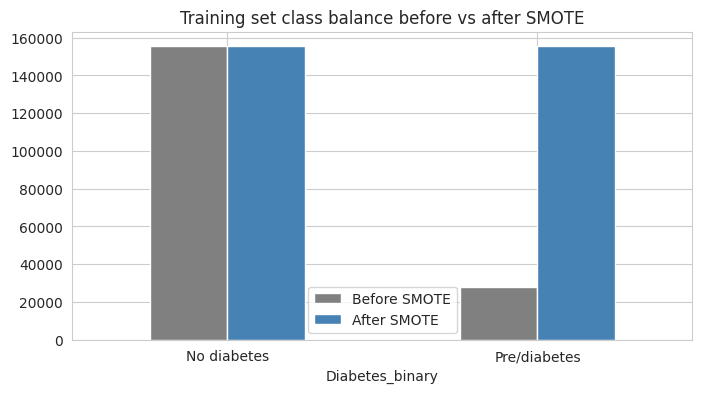

In [6]:
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE

X_clean = clean.drop(columns=[target])
y_clean = clean[target]

# Split FIRST, then apply SMOTE only to the training part (avoids data leakage)
X_train, X_test, y_train, y_test = train_test_split(
    X_clean, y_clean, test_size=0.2, stratify=y_clean, random_state=42)

X_train_sm, y_train_sm = SMOTE(random_state=42).fit_resample(X_train, y_train)

before = y_train.value_counts()
after = y_train_sm.value_counts()
print("Before SMOTE:", before.to_dict())
print("After SMOTE: ", after.to_dict())
print("Test set (untouched):", y_test.value_counts().to_dict())

pd.DataFrame({"Before SMOTE": before, "After SMOTE": after}).plot(kind="bar", color=["grey", "steelblue"])
plt.title("Training set class balance before vs after SMOTE")
plt.xticks([0, 1], ["No diabetes", "Pre/diabetes"], rotation=0)
plt.show()

In [7]:
rows = []
for col in binary_features:
    rate_without = df[df[col] == 0][target].mean() * 100
    rate_with = df[df[col] == 1][target].mean() * 100
    rows.append([col, round(rate_without, 1), round(rate_with, 1)])

factor_table = pd.DataFrame(rows, columns=["Feature", "Rate without (%)", "Rate with (%)"])
factor_table["Difference"] = factor_table["Rate with (%)"] - factor_table["Rate without (%)"]
factor_table = factor_table.sort_values("Difference")
factor_table

,Feature,Rate without (%),Rate with (%),Difference
6,PhysActivity,21.1,11.6,-9.5
9,HvyAlcoholConsump,14.4,5.8,-8.6
8,Veggies,18.0,13.0,-5.0
7,Fruits,15.8,12.9,-2.9
13,Sex,13.0,15.2,2.2
10,AnyHealthcare,11.5,14.1,2.6
11,NoDocbcCost,13.6,17.5,3.9
3,Smoker,12.1,16.3,4.2
2,CholCheck,2.5,14.4,11.9
1,HighChol,8.0,22.0,14.0


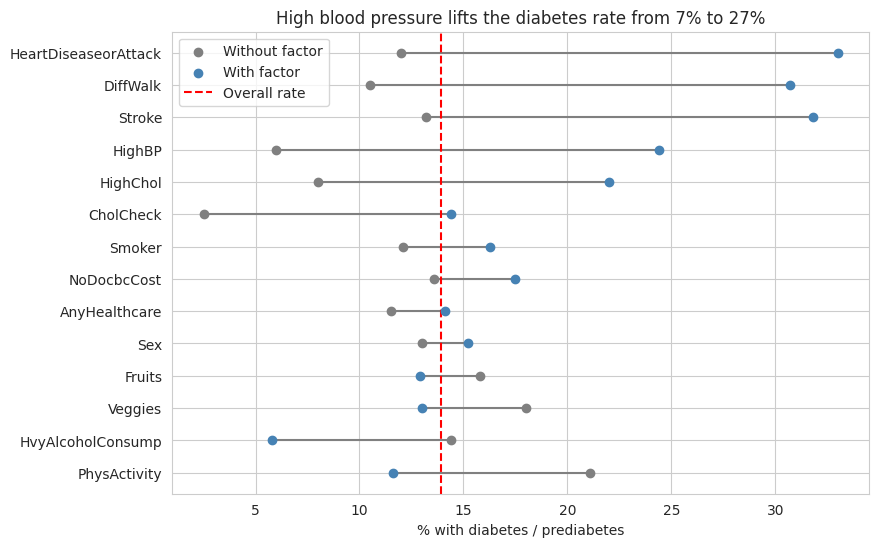

In [8]:
plt.figure(figsize=(9, 6))
y_pos = range(len(factor_table))
plt.hlines(y_pos, factor_table["Rate without (%)"], factor_table["Rate with (%)"], color="grey")
plt.scatter(factor_table["Rate without (%)"], y_pos, color="grey", label="Without factor", zorder=3)
plt.scatter(factor_table["Rate with (%)"], y_pos, color="steelblue", label="With factor", zorder=3)
plt.axvline(df[target].mean() * 100, color="red", linestyle="--", label="Overall rate")
plt.yticks(y_pos, factor_table["Feature"])
plt.xlabel("% with diabetes / prediabetes")
plt.title("High blood pressure lifts the diabetes rate from 7% to 27%")
plt.legend()
plt.show()

In [9]:
from sklearn.feature_selection import mutual_info_classif

corr = df[feature_cols].corrwith(df[target]).round(3)

sample = df.sample(60000, random_state=42)
mi = mutual_info_classif(sample[feature_cols], sample[target],
                         discrete_features=[c != "BMI" for c in feature_cols], random_state=42)

ranking = pd.DataFrame({"Correlation": corr, "Mutual info": mi.round(4)})
ranking = ranking.reindex(ranking["Correlation"].abs().sort_values(ascending=False).index)
ranking

,Correlation,Mutual info
GenHlth,0.294,0.0441
HighBP,0.263,0.0360
DiffWalk,0.218,0.0188
BMI,0.217,0.0278
HighChol,0.200,0.0216
HeartDiseaseorAttack,0.177,0.0115
Age,0.177,0.0208
PhysHlth,0.171,0.0139
Income,-0.164,0.0142
Education,-0.124,0.0076


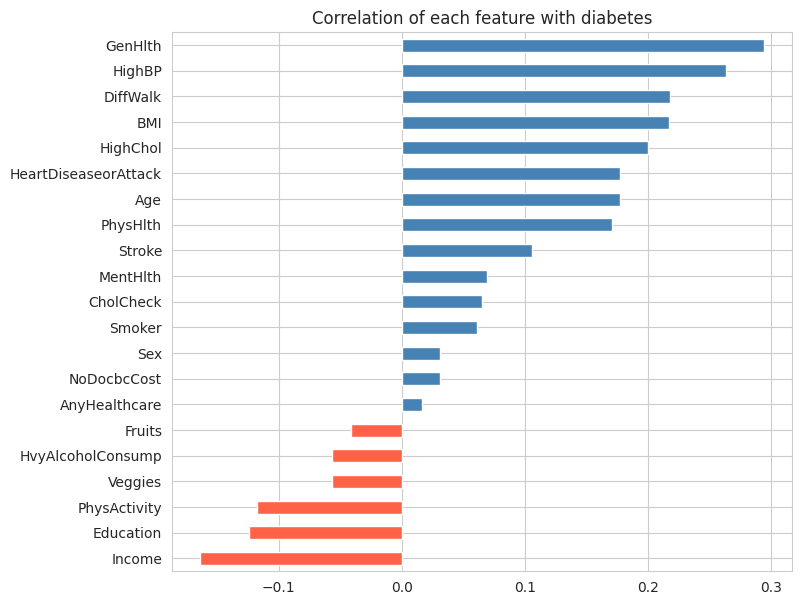

In [10]:
sorted_corr = ranking["Correlation"].sort_values()
sorted_corr.plot(kind="barh", figsize=(8, 7),
                 color=["tomato" if v < 0 else "steelblue" for v in sorted_corr])
plt.title("Correlation of each feature with diabetes")
plt.show()

              Heart disease (%)  Fair/poor health (%)
No diabetes                 7.3                  13.4
Pre/diabetes               22.3                  40.6


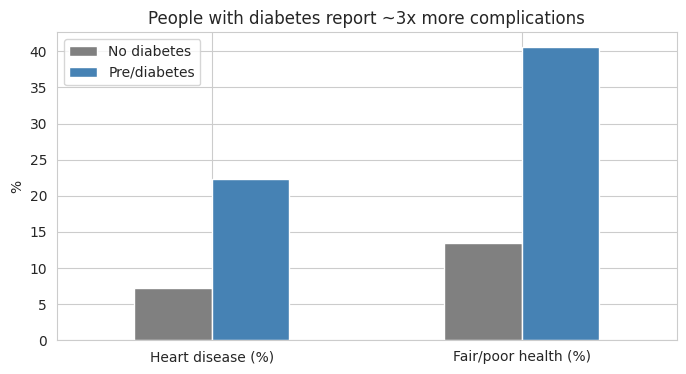

In [11]:
heart = df.groupby(target)["HeartDiseaseorAttack"].mean() * 100
poor_health = df.groupby(target)["GenHlth"].apply(lambda s: (s >= 4).mean() * 100)

q3 = pd.DataFrame({"Heart disease (%)": heart, "Fair/poor health (%)": poor_health}).round(1)
q3.index = ["No diabetes", "Pre/diabetes"]
print(q3)

q3.T.plot(kind="bar", color=["grey", "steelblue"])
plt.title("People with diabetes report ~3x more complications")
plt.ylabel("%")
plt.xticks(rotation=0)
plt.show()

In [12]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier

cv = StratifiedKFold(5, shuffle=True, random_state=42)
y_flat = y.values.ravel()

base_f1 = cross_val_score(DummyClassifier(strategy="most_frequent"), X, y_flat, cv=cv, scoring="f1_macro")
auc = cross_val_score(LogisticRegression(max_iter=2000), X, y_flat, cv=cv, scoring="roc_auc")
print("Majority-class baseline Macro-F1:", round(base_f1.mean(), 3))
print("Logistic regression ROC-AUC:     ", round(auc.mean(), 3))

Majority-class baseline Macro-F1: 0.463
Logistic regression ROC-AUC:      0.822
